## 0. Setup

In [ ]:
import os
import re
import json
import heapq
import random
import requests
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(42)
np.random.seed(42)


In [ ]:
# How many sentences to collect from the raw file into our working pool.
POOL_TARGET_SENTENCES = 1_050_000   # >= 1,000,000 (train) + 1000 (dev) + 1000 (test) + slack

MIN_SENT_LEN = 3     # words
MAX_SENT_LEN = 120   # words

TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]
VOCAB_SIZES = [20_000, 30_000, 50_000]

DEFAULT_VOCAB_SIZE = 30_000     # used while sweeping TRAIN_SIZES
DEFAULT_TRAIN_SIZE = 500_000    # used while sweeping VOCAB_SIZES

MIN_PAIR_FREQ = 2   # standard minimum: don't merge pairs seen only once

CORPUS_PATH="gu.txt"

OUTPUT_DIR = "tokenizer_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


##  Sentence tokenization


In [ ]:
SENT_END_RE = re.compile(r'(?<=[।॥.!?])\s+')
WS_RE = re.compile(r'\s+')
WORD_RE = re.compile(r'[^\W_]+|[^\w\s]', re.UNICODE)


def simple_sentence_tokenize(paragraph: str):
    paragraph = paragraph.strip()
    if not paragraph:
        return []
    paragraph = WS_RE.sub(' ', paragraph)
    return [s.strip() for s in SENT_END_RE.split(paragraph) if s.strip()]


def pre_tokenize(sentence: str):
    """Split a sentence into word tokens (punctuation kept as separate tokens)."""
    return WORD_RE.findall(sentence)


def sentence_len(sentence: str) -> int:
    return len(pre_tokenize(sentence))


In [ ]:
sentence_pool = []
seen = set()

with open(CORPUS_PATH, "r", encoding="utf-8", errors="ignore") as f:
    pbar = tqdm(total=POOL_TARGET_SENTENCES, desc="Collecting sentences")
    for line in f:
        for sent in simple_sentence_tokenize(line):
            L = sentence_len(sent)
            if L < MIN_SENT_LEN or L > MAX_SENT_LEN:
                continue
            if sent in seen:
                continue
            seen.add(sent)
            sentence_pool.append(sent)
            pbar.update(1)
        if len(sentence_pool) >= POOL_TARGET_SENTENCES:
            break
    pbar.close()

print(f"Collected {len(sentence_pool):,} unique sentences from {CORPUS_PATH}.")


Collected 1,050,012 unique sentences from gu.txt.


##  Train / Dev / Test split (length-stratified dev & test)


In [ ]:
def stratified_sample_by_length(pool_indices, lengths, n_samples, n_bins=10, rng=random):
    lens_sorted = sorted(lengths[i] for i in pool_indices)
    edges = []
    for q in range(1, n_bins):
        idx = int(len(lens_sorted) * q / n_bins)
        edges.append(lens_sorted[min(idx, len(lens_sorted) - 1)])
    edges = sorted(set(edges))

    def bin_of(length):
        b = 0
        for e in edges:
            if length > e:
                b += 1
            else:
                break
        return b

    buckets = defaultdict(list)
    for i in pool_indices:
        buckets[bin_of(lengths[i])].append(i)
    for b in buckets:
        rng.shuffle(buckets[b])

    per_bin = max(1, n_samples // max(1, len(buckets)))
    chosen = []
    bucket_keys = list(buckets.keys())
    rng.shuffle(bucket_keys)

    for b in bucket_keys:
        take = buckets[b][:per_bin]
        chosen.extend(take)
        buckets[b] = buckets[b][per_bin:]

    i = 0
    while len(chosen) < n_samples:
        b = bucket_keys[i % len(bucket_keys)]
        if buckets[b]:
            chosen.append(buckets[b].pop())
        i += 1
        if i > 10 * n_samples and all(len(v) == 0 for v in buckets.values()):
            break

    return chosen[:n_samples]


lengths = [sentence_len(s) for s in sentence_pool]
all_indices = list(range(len(sentence_pool)))
random.shuffle(all_indices)

dev_indices = stratified_sample_by_length(all_indices, lengths, 1000)
remaining_after_dev = [i for i in all_indices if i not in set(dev_indices)]
test_indices = stratified_sample_by_length(remaining_after_dev, lengths, 1000)

used = set(dev_indices) | set(test_indices)
train_pool_indices = [i for i in all_indices if i not in used]

dev_sentences = [sentence_pool[i] for i in dev_indices]
test_sentences = [sentence_pool[i] for i in test_indices]
train_pool = [sentence_pool[i] for i in train_pool_indices]

print(f"Train pool: {len(train_pool):,} | Dev: {len(dev_sentences):,} | Test: {len(test_sentences):,}")
assert len(dev_sentences) == 1000 and len(test_sentences) == 1000
assert max(TRAIN_SIZES) <= len(train_pool), "Increase POOL_TARGET_SENTENCES to cover the largest TRAIN_SIZE."


Train pool: 1,048,012 | Dev: 1,000 | Test: 1,000


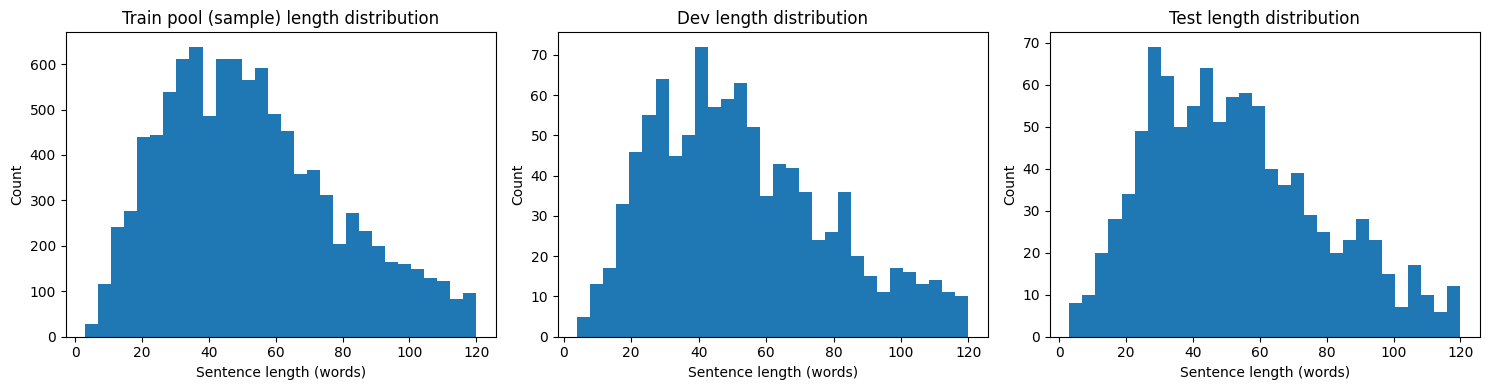

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist([sentence_len(s) for s in train_pool[:10000]], bins=30)
axes[0].set_title("Train pool (sample) length distribution")

axes[1].hist([sentence_len(s) for s in dev_sentences], bins=30)
axes[1].set_title("Dev length distribution")

axes[2].hist([sentence_len(s) for s in test_sentences], bins=30)
axes[2].set_title("Test length distribution")

for ax in axes:
    ax.set_xlabel("Sentence length (words)")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


In [ ]:
with open(os.path.join(OUTPUT_DIR, "train_pool.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(train_pool))
with open(os.path.join(OUTPUT_DIR, "dev.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(dev_sentences))
with open(os.path.join(OUTPUT_DIR, "test.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(test_sentences))
print("Saved train_pool.txt, dev.txt, test.txt to", OUTPUT_DIR)


Saved train_pool.txt, dev.txt, test.txt to tokenizer_outputs


## BPE from scratch


In [ ]:
def word_freqs_from_sentences(sentences):
    wf = Counter()
    for s in sentences:
        for w in pre_tokenize(s):
            wf[w] += 1
    return wf


def bpe_init_vocab(word_freq):
    """word (str) -> tuple of symbols, frequency"""
    vocab = {}
    for word, freq in word_freq.items():
        symbols = tuple(list(word) + ["</w>"])
        vocab[symbols] = vocab.get(symbols, 0) + freq
    return vocab


def bpe_merge_symbols(s1, s2):
    return s1 + s2


def train_bpe(word_freq, vocab_size, min_pair_freq=MIN_PAIR_FREQ, verbose=True):
    vocab = bpe_init_vocab(word_freq)          # word_tuple -> freq
    pair_counts = Counter()                     # pair -> total freq
    pair_index = defaultdict(set)                # pair -> set of word_tuples containing it

    base_symbols = set()
    for word_tuple, freq in vocab.items():
        base_symbols.update(word_tuple)
        for i in range(len(word_tuple) - 1):
            p = (word_tuple[i], word_tuple[i + 1])
            pair_counts[p] += freq
            pair_index[p].add(word_tuple)

    merges = []                # ordered list of merged pairs
    vocab_symbols = set(base_symbols)

    n_merges_needed = max(0, vocab_size - len(vocab_symbols))
    pbar = tqdm(total=n_merges_needed, desc="Training BPE", disable=not verbose)

    while len(vocab_symbols) < vocab_size:
        if not pair_counts:
            break
        best_pair, best_freq = max(pair_counts.items(), key=lambda kv: (kv[1], kv[0]))
        if best_freq < min_pair_freq:
            break

        affected_words = list(pair_index.get(best_pair, ()))
        for word_tuple in affected_words:
            freq = vocab.get(word_tuple)
            if freq is None:
                continue

            # remove old contributions of this word
            for i in range(len(word_tuple) - 1):
                p = (word_tuple[i], word_tuple[i + 1])
                pair_counts[p] -= freq
                if pair_counts[p] <= 0:
                    del pair_counts[p]
                pair_index[p].discard(word_tuple)
                if not pair_index[p]:
                    del pair_index[p]

            # build the merged word
            new_word = []
            i = 0
            while i < len(word_tuple):
                if i < len(word_tuple) - 1 and (word_tuple[i], word_tuple[i + 1]) == best_pair:
                    new_word.append(bpe_merge_symbols(word_tuple[i], word_tuple[i + 1]))
                    i += 2
                else:
                    new_word.append(word_tuple[i])
                    i += 1
            new_word = tuple(new_word)

            del vocab[word_tuple]
            vocab[new_word] = vocab.get(new_word, 0) + freq

            # add new contributions
            for i in range(len(new_word) - 1):
                p = (new_word[i], new_word[i + 1])
                pair_counts[p] = pair_counts.get(p, 0) + freq
                pair_index[p].add(new_word)

        merges.append(best_pair)
        vocab_symbols.add(bpe_merge_symbols(*best_pair))
        pbar.update(1)

    pbar.close()
    merge_rank = {pair: rank for rank, pair in enumerate(merges)}
    return {"merges": merges, "merge_rank": merge_rank, "vocab_symbols": vocab_symbols}


def bpe_tokenize_word(word, merge_rank, cache=None):
    if cache is not None and word in cache:
        return cache[word]
    symbols = list(word) + ["</w>"]
    while len(symbols) > 1:
        pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        ranked = [(merge_rank[p], idx) for idx, p in enumerate(pairs) if p in merge_rank]
        if not ranked:
            break
        _, idx = min(ranked)
        merged = bpe_merge_symbols(symbols[idx], symbols[idx + 1])
        symbols = symbols[:idx] + [merged] + symbols[idx + 2:]
    if cache is not None:
        cache[word] = symbols
    return symbols


def bpe_tokenize_sentence(sentence, model, cache=None):
    tokens = []
    for w in pre_tokenize(sentence):
        tokens.extend(bpe_tokenize_word(w, model["merge_rank"], cache=cache))
    return tokens


##  WordPiece from scratch



In [ ]:
def wp_init_vocab(word_freq):
    vocab = {}
    for word, freq in word_freq.items():
        chars = list(word)
        symbols = tuple([chars[0]] + ["##" + c for c in chars[1:]]) if chars else tuple()
        if symbols:
            vocab[symbols] = vocab.get(symbols, 0) + freq
    return vocab


def wp_merge_symbols(s1, s2):
    left = s1[2:] if s1.startswith("##") else s1
    right = s2[2:] if s2.startswith("##") else s2
    merged = left + right
    return "##" + merged if s1.startswith("##") else merged


def train_wordpiece(word_freq, vocab_size, min_pair_freq=MIN_PAIR_FREQ, verbose=True):
    vocab = wp_init_vocab(word_freq)             # word_tuple -> freq
    pair_counts = Counter()
    pair_index = defaultdict(set)
    symbol_counts = Counter()                     # unigram freq of each symbol

    base_symbols = set()
    for word_tuple, freq in vocab.items():
        base_symbols.update(word_tuple)
        for sym in word_tuple:
            symbol_counts[sym] += freq
        for i in range(len(word_tuple) - 1):
            p = (word_tuple[i], word_tuple[i + 1])
            pair_counts[p] += freq
            pair_index[p].add(word_tuple)

    vocab_symbols = set(base_symbols)
    n_merges_needed = max(0, vocab_size - len(vocab_symbols))
    pbar = tqdm(total=n_merges_needed, desc="Training WordPiece", disable=not verbose)

    while len(vocab_symbols) < vocab_size:
        candidates = [(p, c) for p, c in pair_counts.items() if c >= min_pair_freq]
        if not candidates:
            break

        def score(item):
            p, c = item
            denom = symbol_counts[p[0]] * symbol_counts[p[1]]
            return (c / denom) if denom > 0 else 0.0

        best_pair, best_freq = max(candidates, key=lambda item: (score(item), item[1], item[0]))

        affected_words = list(pair_index.get(best_pair, ()))
        for word_tuple in affected_words:
            freq = vocab.get(word_tuple)
            if freq is None:
                continue

            for i in range(len(word_tuple) - 1):
                p = (word_tuple[i], word_tuple[i + 1])
                pair_counts[p] -= freq
                if pair_counts[p] <= 0:
                    del pair_counts[p]
                pair_index[p].discard(word_tuple)
                if not pair_index[p]:
                    del pair_index[p]
            for sym in word_tuple:
                symbol_counts[sym] -= freq
                if symbol_counts[sym] <= 0:
                    del symbol_counts[sym]

            new_word = []
            i = 0
            while i < len(word_tuple):
                if i < len(word_tuple) - 1 and (word_tuple[i], word_tuple[i + 1]) == best_pair:
                    new_word.append(wp_merge_symbols(word_tuple[i], word_tuple[i + 1]))
                    i += 2
                else:
                    new_word.append(word_tuple[i])
                    i += 1
            new_word = tuple(new_word)

            del vocab[word_tuple]
            vocab[new_word] = vocab.get(new_word, 0) + freq

            for sym in new_word:
                symbol_counts[sym] = symbol_counts.get(sym, 0) + freq
            for i in range(len(new_word) - 1):
                p = (new_word[i], new_word[i + 1])
                pair_counts[p] = pair_counts.get(p, 0) + freq
                pair_index[p].add(new_word)

        vocab_symbols.add(wp_merge_symbols(*best_pair))
        pbar.update(1)

    pbar.close()
    return {"vocab_symbols": vocab_symbols}


def wordpiece_tokenize_word(word, vocab_symbols, cache=None, max_chars=200):
    if cache is not None and word in cache:
        return cache[word]
    if len(word) == 0:
        return []
    if len(word) > max_chars:
        result = ["[UNK]"]
        if cache is not None:
            cache[word] = result
        return result

    tokens = []
    start = 0
    is_bad = False
    while start < len(word):
        end = len(word)
        cur = None
        while start < end:
            substr = word[start:end]
            if start > 0:
                substr = "##" + substr
            if substr in vocab_symbols:
                cur = substr
                break
            end -= 1
        if cur is None:
            is_bad = True
            break
        tokens.append(cur)
        start = end

    result = ["[UNK]"] if is_bad else tokens
    if cache is not None:
        cache[word] = result
    return result


def wordpiece_tokenize_sentence(sentence, model, cache=None):
    tokens = []
    for w in pre_tokenize(sentence):
        tokens.extend(wordpiece_tokenize_word(w, model["vocab_symbols"], cache=cache))
    return tokens


In [ ]:
_sample_wf = word_freqs_from_sentences(train_pool[:2000])
_bpe_small = train_bpe(_sample_wf, vocab_size=len(set("".join(_sample_wf))) + 200, verbose=True)
_wp_small  = train_wordpiece(_sample_wf, vocab_size=len(set("".join(_sample_wf))) + 200, verbose=True)

for s in dev_sentences[:3]:
    print("SENTENCE:", s)
    print("  BPE      :", bpe_tokenize_sentence(s, _bpe_small))
    print("  WordPiece:", wordpiece_tokenize_sentence(s, _wp_small))
    print()


Training BPE:   0%|          | 0/199 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/108 [00:00<?, ?it/s]

SENTENCE: તે અવેતન આવક (અથવા અન્ય) કર પણ શામેલ કરી શકે છે
  BPE      : ['ત</w>', 'ે</w>', 'અ', 'વ</w>', 'ે</w>', 'તન</w>', 'આવ', 'ક</w>', '(</w>', 'અ', 'થવ</w>', 'ા</w>', 'અન</w>', '્</w>', 'ય</w>', ')</w>', 'કર</w>', 'પણ</w>', 'શ</w>', 'ા</w>', 'મ</w>', 'ે</w>', 'લ</w>', 'કર</w>', 'ી</w>', 'શક</w>', 'ે</w>', 'છ</w>', 'ે</w>']
  WordPiece: ['ત', 'ે', 'અ', '##વ', 'ે', 'ત', '##ન', 'આ', '##વ', '##ક', '(', 'અ', '##થ', '##વ', 'ા', 'અ', '##ન', '્', 'ય', ')', 'ક', '##ર', 'પ', '##ણ', 'શ', 'ા', 'મ', 'ે', 'લ', 'ક', '##ર', 'ી', 'શ', '##ક', 'ે', 'છ', 'ે']

SENTENCE: જેના ભાગરૃપે ગુરૃવારે ભરૃચ કલેકટર ડો.
  BPE      : ['જ</w>', 'ે</w>', 'ન</w>', 'ા</w>', 'ભ</w>', 'ા</w>', 'ગર</w>', 'ૃ</w>', 'પ</w>', 'ે</w>', 'ગ</w>', 'ુ</w>', 'ર</w>', 'ૃ</w>', 'વ</w>', 'ા</w>', 'ર</w>', 'ે</w>', 'ભ', 'ર</w>', 'ૃ</w>', 'ચ</w>', 'કલ</w>', 'ે</w>', 'ક', 'ટર</w>', 'ડ</w>', 'ો</w>', '.</w>']
  WordPiece: ['જ', 'ે', 'ન', 'ા', 'ભ', 'ા', 'ગ', '##ર', 'ૃ', 'પ', 'ે', 'ગ', 'ુ', 'ર', 'ૃ', 'વ', 'ા', 'ર', 'ે', 'ભ', '##ર', 'ૃ', 'ચ'

##  Evaluation metrics

For a trained tokenizer, on dev/test we report:
- **avg tokens / sentence** — lower = more compact representation
- **avg tokens / word** (subword fertility) — how many pieces the average word is split into
- **unk_rate_pct** — `[UNK]` tokens (WordPiece) or unmerged raw characters not present in the
  learned vocabulary (BPE) as a % of all output tokens
- **type_token_ratio** — unique tokens / total tokens produced, over dev+test
- **actual_vocab_size** — size of the learned vocabulary


In [ ]:
def evaluate_bpe(model, sentences):
    cache = {}
    total_tokens = total_words = unk_count = 0
    all_tokens = []
    vocab_symbols = model["vocab_symbols"]
    for s in sentences:
        toks = bpe_tokenize_sentence(s, model, cache=cache)
        total_tokens += len(toks)
        total_words += len(pre_tokenize(s))
        unk_count += sum(1 for t in toks if t not in vocab_symbols)
        all_tokens.extend(toks)
    n = len(sentences)
    return {
        "avg_tokens_per_sentence": total_tokens / n,
        "avg_tokens_per_word": total_tokens / max(1, total_words),
        "unk_rate_pct": 100.0 * unk_count / max(1, total_tokens),
        "type_token_ratio": len(set(all_tokens)) / max(1, len(all_tokens)),
        "actual_vocab_size": len(vocab_symbols),
    }


def evaluate_wordpiece(model, sentences):
    cache = {}
    total_tokens = total_words = unk_count = 0
    all_tokens = []
    for s in sentences:
        toks = wordpiece_tokenize_sentence(s, model, cache=cache)
        total_tokens += len(toks)
        total_words += len(pre_tokenize(s))
        unk_count += sum(1 for t in toks if t == "[UNK]")
        all_tokens.extend(toks)
    n = len(sentences)
    return {
        "avg_tokens_per_sentence": total_tokens / n,
        "avg_tokens_per_word": total_tokens / max(1, total_words),
        "unk_rate_pct": 100.0 * unk_count / max(1, total_tokens),
        "type_token_ratio": len(set(all_tokens)) / max(1, len(all_tokens)),
        "actual_vocab_size": len(model["vocab_symbols"]),
    }


def run_experiment(train_sentences, vocab_size, tag):
    word_freq = word_freqs_from_sentences(train_sentences)

    bpe_model = train_bpe(word_freq, vocab_size)
    wp_model  = train_wordpiece(word_freq, vocab_size)

    with open(os.path.join(OUTPUT_DIR, f"bpe_{tag}.json"), "w", encoding="utf-8") as f:
        json.dump({"merges": [list(p) for p in bpe_model["merges"]],
                    "vocab_symbols": sorted(bpe_model["vocab_symbols"])}, f, ensure_ascii=False)
        
    with open(os.path.join(OUTPUT_DIR, f"wordpiece_{tag}.json"), "w", encoding="utf-8") as f:
        json.dump({"vocab_symbols": sorted(wp_model["vocab_symbols"])}, f, ensure_ascii=False)

    results = {
        "BPE": {"dev": evaluate_bpe(bpe_model, dev_sentences),
                "test": evaluate_bpe(bpe_model, test_sentences)},
        "WordPiece": {"dev": evaluate_wordpiece(wp_model, dev_sentences),
                       "test": evaluate_wordpiece(wp_model, test_sentences)},
    }
    return results, bpe_model, wp_model


##  effect of training-data size


TRAIN_SIZES = [100000, 300000, 500000, 1000000]


In [ ]:
size_results = []

for size in TRAIN_SIZES:
    print(f"--- Training size = {size:,} ---")
    subset = train_pool[:size]
    res, _, _ = run_experiment(subset, DEFAULT_VOCAB_SIZE, tag=f"size{size}")
    for method in ("BPE", "WordPiece"):
        for split in ("dev", "test"):
            row = {"train_size": size, "vocab_size": DEFAULT_VOCAB_SIZE,
                   "method": method, "split": split}
            row.update(res[method][split])
            size_results.append(row)

df_size = pd.DataFrame(size_results)
df_size


--- Training size = 100,000 ---


Training BPE:   0%|          | 0/29667 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/29534 [00:00<?, ?it/s]

--- Training size = 300,000 ---


Training BPE:   0%|          | 0/29558 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/29409 [00:00<?, ?it/s]

... (3 outputs left out)

--- Training size = 1,000,000 ---


Training BPE:   0%|          | 0/29389 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/29201 [00:00<?, ?it/s]

,train_size,vocab_size,method,split,avg_tokens_per_sentence,avg_tokens_per_word,unk_rate_pct,type_token_ratio,actual_vocab_size
0,100000,30000,BPE,dev,53.273,1.003560,0.001877,0.034652,12345
1,100000,30000,BPE,test,53.052,1.002987,0.000000,0.032666,12345
2,100000,30000,WordPiece,dev,53.260,1.003315,0.001878,0.034472,15016
3,100000,30000,WordPiece,test,53.055,1.003044,0.000000,0.032872,15016
4,300000,30000,BPE,dev,53.197,1.002129,0.000000,0.034457,22174
5,300000,30000,BPE,test,52.989,1.001796,0.000000,0.032799,22174
6,300000,30000,WordPiece,dev,53.180,1.001808,0.000000,0.034336,28493
7,300000,30000,WordPiece,test,52.982,1.001664,0.000000,0.032709,28493
8,500000,30000,BPE,dev,53.166,1.001545,0.000000,0.034251,29391
9,500000,30000,BPE,test,52.964,1.001323,0.000000,0.032683,29391


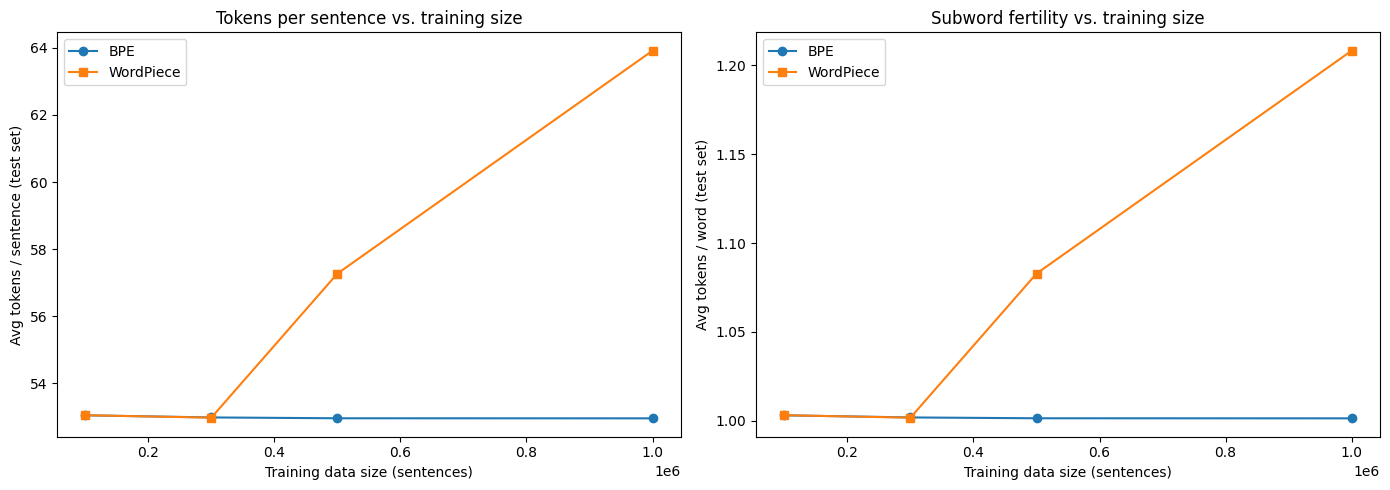

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for method, marker in [("BPE", "o"), ("WordPiece", "s")]:
    sub = df_size[(df_size.method == method) & (df_size.split == "test")]
    axes[0].plot(sub.train_size, sub.avg_tokens_per_sentence, marker=marker, label=method)
    axes[1].plot(sub.train_size, sub.avg_tokens_per_word, marker=marker, label=method)

axes[0].set_xlabel("Training data size (sentences)")
axes[0].set_ylabel("Avg tokens / sentence (test set)")
axes[0].set_title("Tokens per sentence vs. training size")
axes[0].legend()

axes[1].set_xlabel("Training data size (sentences)")
axes[1].set_ylabel("Avg tokens / word (test set)")
axes[1].set_title("Subword fertility vs. training size")
axes[1].legend()

plt.tight_layout()
plt.show()


##  effect of vocabulary size

VOCAB_SIZES = [20000, 30000, 50000]


In [ ]:
vocab_results = []
fixed_train_subset = train_pool[:DEFAULT_TRAIN_SIZE]

for vsize in VOCAB_SIZES:
    print(f"--- Vocab size = {vsize:,} ---")
    res, _, _ = run_experiment(fixed_train_subset, vsize, tag=f"vocab{vsize}")
    for method in ("BPE", "WordPiece"):
        for split in ("dev", "test"):
            row = {"train_size": DEFAULT_TRAIN_SIZE, "vocab_size": vsize,
                   "method": method, "split": split}
            row.update(res[method][split])
            vocab_results.append(row)

df_vocab = pd.DataFrame(vocab_results)
df_vocab


--- Vocab size = 20,000 ---


Training BPE:   0%|          | 0/19481 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/19320 [00:00<?, ?it/s]

--- Vocab size = 30,000 ---


Training BPE:   0%|          | 0/29481 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/29320 [00:00<?, ?it/s]

--- Vocab size = 50,000 ---


Training BPE:   0%|          | 0/49481 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/49320 [00:00<?, ?it/s]

,train_size,vocab_size,method,split,avg_tokens_per_sentence,avg_tokens_per_word,unk_rate_pct,type_token_ratio,actual_vocab_size
0,500000,20000,BPE,dev,53.199,1.002166,0.0,0.034456,20000
1,500000,20000,BPE,test,52.998,1.001966,0.0,0.032945,20000
2,500000,20000,WordPiece,dev,63.932,1.204355,0.0,0.005475,20000
3,500000,20000,WordPiece,test,63.647,1.203293,0.0,0.005468,20000
4,500000,30000,BPE,dev,53.166,1.001545,0.0,0.034251,29391
5,500000,30000,BPE,test,52.964,1.001323,0.0,0.032683,29391
6,500000,30000,WordPiece,dev,57.623,1.085506,0.0,0.018100,30000
7,500000,30000,WordPiece,test,57.273,1.082788,0.0,0.017670,30000
8,500000,50000,BPE,dev,53.166,1.001545,0.0,0.034251,29391
9,500000,50000,BPE,test,52.964,1.001323,0.0,0.032683,29391


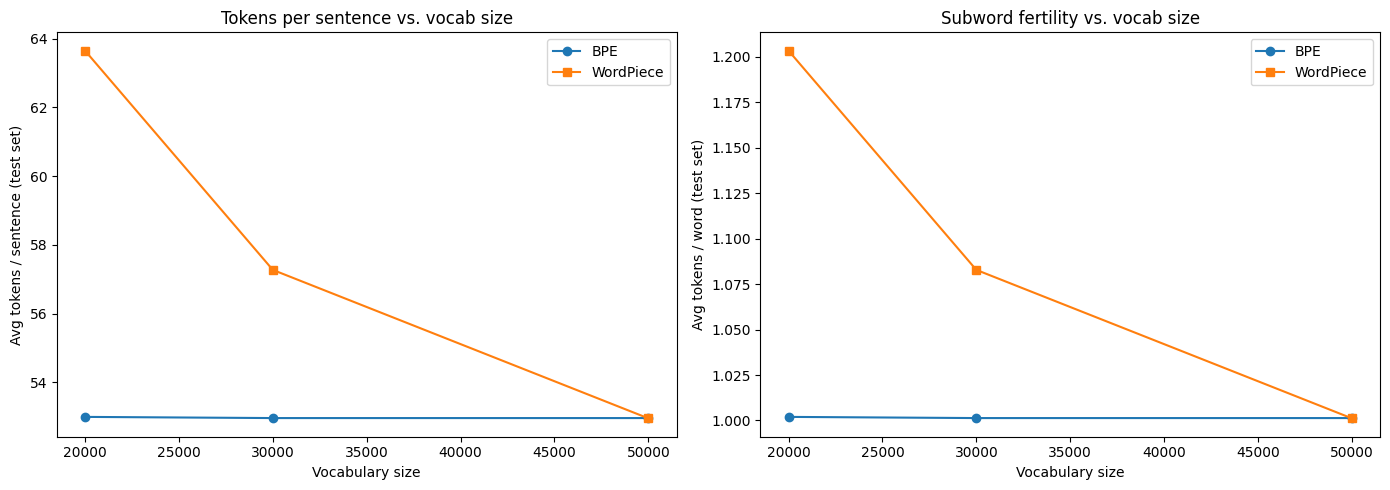

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for method, marker in [("BPE", "o"), ("WordPiece", "s")]:
    sub = df_vocab[(df_vocab.method == method) & (df_vocab.split == "test")]
    axes[0].plot(sub.vocab_size, sub.avg_tokens_per_sentence, marker=marker, label=method)
    axes[1].plot(sub.vocab_size, sub.avg_tokens_per_word, marker=marker, label=method)

axes[0].set_xlabel("Vocabulary size")
axes[0].set_ylabel("Avg tokens / sentence (test set)")
axes[0].set_title("Tokens per sentence vs. vocab size")
axes[0].legend()

axes[1].set_xlabel("Vocabulary size")
axes[1].set_ylabel("Avg tokens / word (test set)")
axes[1].set_title("Subword fertility vs. vocab size")
axes[1].legend()

plt.tight_layout()
plt.show()


## 11. Qualitative comparison

Using tokenizers trained at `DEFAULT_TRAIN_SIZE` / `DEFAULT_VOCAB_SIZE`.


In [ ]:
_, bpe_final, wp_final = run_experiment(fixed_train_subset, DEFAULT_VOCAB_SIZE, tag="final_demo")

sample_sentences = random.sample(dev_sentences, 5)
for s in sample_sentences:
    print("SENTENCE:", s)
    print("  BPE      :", bpe_tokenize_sentence(s, bpe_final))
    print("  WordPiece:", wordpiece_tokenize_sentence(s, wp_final))
    print()


Training BPE:   0%|          | 0/29481 [00:00<?, ?it/s]

Training WordPiece:   0%|          | 0/29320 [00:00<?, ?it/s]

SENTENCE: કર્ક – ડ, હ (Cancer): આજનો દિવસ તમારા માટે મુશ્કેલી ભર્યો હોઈ શકે છે.
  BPE      : ['કર</w>', '્</w>', 'ક</w>', '–</w>', 'ડ</w>', ',</w>', 'હ</w>', '(</w>', 'Cancer</w>', ')</w>', ':</w>', 'આજન</w>', 'ો</w>', 'દ</w>', 'િ</w>', 'વસ</w>', 'તમ</w>', 'ા</w>', 'ર</w>', 'ા</w>', 'મ</w>', 'ા</w>', 'ટ</w>', 'ે</w>', 'મ</w>', 'ુ</w>', 'શ</w>', '્</w>', 'ક</w>', 'ે</w>', 'લ</w>', 'ી</w>', 'ભર</w>', '્</w>', 'ય</w>', 'ો</w>', 'હ</w>', 'ો</w>', 'ઈ</w>', 'શક</w>', 'ે</w>', 'છ</w>', 'ે</w>', '.</w>']
  WordPiece: ['કર', '્', 'ક', '–', 'ડ', ',', 'હ', '(', 'Cancer', ')', ':', 'આજ', '##ન', 'ો', 'દ', 'િ', 'વસ', 'ત', '##મ', 'ા', 'ર', 'ા', 'મ', 'ા', 'ટ', 'ે', 'મ', 'ુ', 'શ', '્', 'ક', 'ે', 'લ', 'ી', 'ભ', '##ર', '્', 'ય', 'ો', 'હ', 'ો', 'ઈ', 'શક', 'ે', 'છ', 'ે', '.']

SENTENCE: વીજળી પડવાને કારણે ૨ લોકોનાં ઘટનાસ્થળે જ મોત નિપજ્યા હતા.
  BPE      : ['વ</w>', 'ી</w>', 'જળ</w>', 'ી</w>', 'પડવ</w>', 'ા</w>', 'ન</w>', 'ે</w>', 'ક</w>', 'ા</w>', 'રણ</w>', 'ે</w>', '૨</w>', 'લ</w>', 'ો</w>', 'ક</w>', 'ો<

## 12. Save summary tables

In [ ]:
df_size.to_csv(os.path.join(OUTPUT_DIR, "results_by_train_size.csv"), index=False)
df_vocab.to_csv(os.path.join(OUTPUT_DIR, "results_by_vocab_size.csv"), index=False)
print("Saved results_by_train_size.csv and results_by_vocab_size.csv to", OUTPUT_DIR)


Saved results_by_train_size.csv and results_by_vocab_size.csv to tokenizer_outputs


## 13. Observations (fill in after running)

- **Training-data size (100k → 1M):** does avg tokens/sentence go down as more merges become
  well-supported by data? Does the UNK rate drop?
- **Vocabulary size (20k → 50k):** do sentences get represented in fewer tokens as more whole
  words/longer subwords enter the vocabulary? What's the trade-off (vocabulary storage cost,
  embedding table size) against that gain?
- **BPE vs WordPiece:** which produces shorter token sequences on your language, which has a
  lower UNK rate, and how does WordPiece's likelihood-based merge criterion (favoring rare
  co-occurring pairs) differ in practice from BPE's raw-frequency criterion?
